In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [7]:
print(df.shape)

(7043, 21)


In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [10]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [11]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [12]:
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


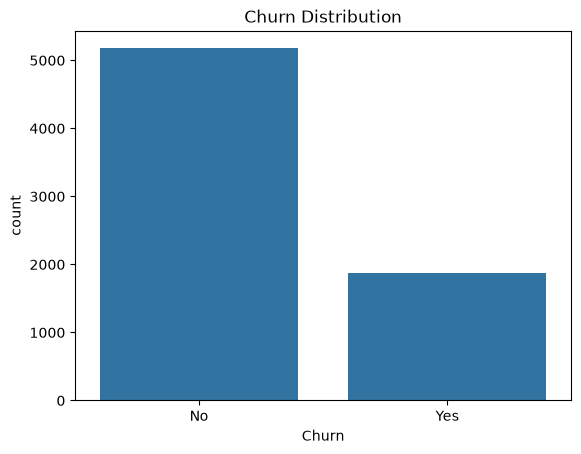

In [13]:
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.show()

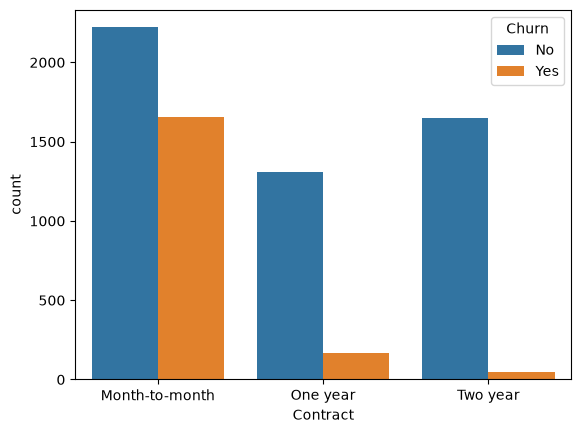

In [14]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.show()

In [15]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [18]:
df = df.drop("customerID", axis=1)

In [19]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df = df.dropna()

Missing TotalCharges: 11


In [20]:
df = df.replace({"No internet service": "No", "No phone service": "No"})

In [21]:
yes_no_cols = ["Partner", "Dependents", "PhoneService", "MultipleLines",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection",
               "TechSupport", "StreamingTV", "StreamingMovies",
               "PaperlessBilling", "Churn"]
for col in yes_no_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0})

df["gender"] = df["gender"].map({"Female": 1, "Male": 0})

In [22]:
df = pd.get_dummies(df, columns=["InternetService", "Contract", "PaymentMethod"],
                    drop_first=True, dtype=int)

In [23]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [24]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(X_train.shape, X_test.shape)
print(X_train.head())

(5625, 23) (1407, 23)
      gender  SeniorCitizen  Partner  Dependents    tenure  PhoneService  \
1413       0              0        1           1  1.321816             1   
7003       0              0        0           0 -0.267410             0   
3355       1              0        1           0  1.444064             1   
4494       0              0        0           0 -1.204646             1   
3541       1              0        1           0  0.669826             0   

      MultipleLines  OnlineSecurity  OnlineBackup  DeviceProtection  ...  \
1413              1               1             1                 1  ...   
7003              0               0             0                 1  ...   
3355              1               0             1                 1  ...   
4494              0               0             1                 0  ...   
3541              0               1             0                 0  ...   

      PaperlessBilling  MonthlyCharges  TotalCharges  \
1413    

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [26]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [27]:
y_pred = log_model.predict(X_test)

In [28]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8031272210376688


In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



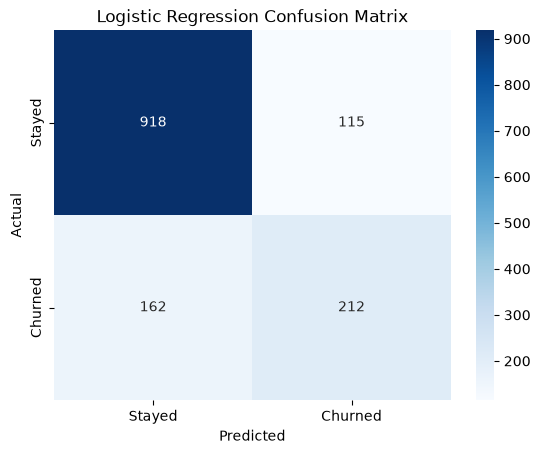

In [30]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"],
            yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [31]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [32]:
tf.random.set_seed(42)
np.random.seed(42)

In [33]:
X_train_nn = X_train.astype("float32")
X_test_nn = X_test.astype("float32")

In [34]:
model = keras.Sequential([
    layers.Input(shape=(X_train_nn.shape[1],)),   # 23 input features
    layers.Dense(16, activation="relu"),          # hidden layer 1
    layers.Dropout(0.3),
    layers.Dense(8, activation="relu"),           # hidden layer 2
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")         # output layer
])

In [35]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 8)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 529 (2.07 KB)

 Trainable params: 529 (2.07 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [37]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [38]:
history = model.fit(
    X_train_nn, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.6464 - loss: 0.6316 - val_accuracy: 0.7404 - val_loss: 0.5022
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7438 - loss: 0.5125 - val_accuracy: 0.7573 - val_loss: 0.4425
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7629 - loss: 0.4807 - val_accuracy: 0.7938 - val_loss: 0.4237
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7682 - loss: 0.4652 - val_accuracy: 0.8044 - val_loss: 0.4173
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7709 - loss: 0.4631 - val_accuracy: 0.8053 - val_loss: 0.4144
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7867 - loss: 0.4538 - val_accuracy: 0.8036 - val_loss: 0.4116
Epoch 7/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7816 - loss: 0.4546 - val_accuracy: 0.8044 - val_loss: 0.4109
Epoch 8/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7867 - loss: 0.4441 - val_

In [39]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

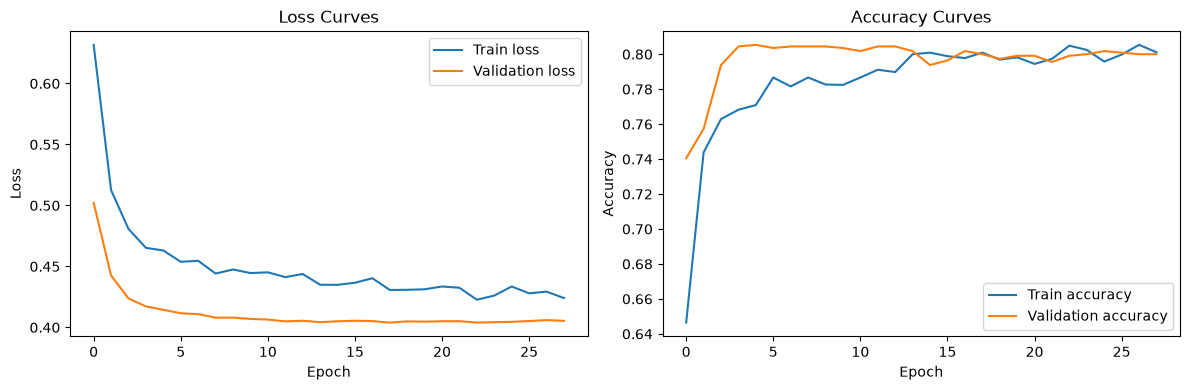

In [40]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curves")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Curves")
plt.legend()

plt.tight_layout()
plt.show()

In [41]:
y_prob = model.predict(X_test_nn)                 # probabilities between 0 and 1
y_pred_nn = (y_prob > 0.5).astype(int).ravel()    # 1 if probability > 0.5

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


In [42]:
print("Accuracy:", accuracy_score(y_test, y_pred_nn))
print(classification_report(y_test, y_pred_nn))

Accuracy: 0.7960199004975125
              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1033
           1       0.65      0.50      0.57       374

    accuracy                           0.80      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.80      0.79      1407



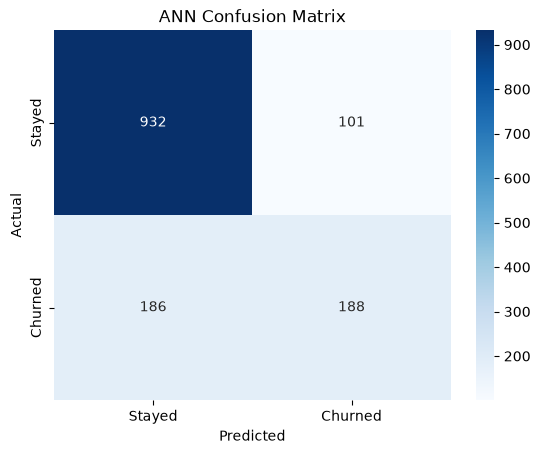

In [43]:
cm_nn = confusion_matrix(y_test, y_pred_nn)
sns.heatmap(cm_nn, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"],
            yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")
plt.show()

In [44]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "ANN"],
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_nn)],
    "Precision (Churn)": [precision_score(y_test, y_pred), precision_score(y_test, y_pred_nn)],
    "Recall (Churn)": [recall_score(y_test, y_pred), recall_score(y_test, y_pred_nn)],
    "F1 (Churn)": [f1_score(y_test, y_pred), f1_score(y_test, y_pred_nn)],
}).round(3)
print(results)

                 Model  Accuracy  Precision (Churn)  Recall (Churn)  \
0  Logistic Regression     0.803              0.648           0.567   
1                  ANN     0.796              0.651           0.503   

   F1 (Churn)  
0       0.605  
1       0.567  


In [45]:
from sklearn.utils.class_weight import compute_class_weight

In [46]:
# ---------- Idea A: find a better threshold ----------
# Use the validation rows (last 20% of the training data, the same ones Keras used)
split = int(len(X_train_nn) * 0.8)
X_val = X_train_nn.iloc[split:]
y_val = y_train.iloc[split:]

val_prob = model.predict(X_val).ravel()
test_prob = model.predict(X_test_nn).ravel()

best_t, best_f1 = 0.5, 0
for t in np.arange(0.20, 0.65, 0.05):
    f1 = f1_score(y_val, (val_prob > t).astype(int))
    if f1 > best_f1:
        best_t, best_f1 = t, f1
print("Best threshold on validation data:", round(best_t, 2))

y_pred_thr = (test_prob > best_t).astype(int)
print(classification_report(y_test, y_pred_thr))

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Best threshold on validation data: 0.3
              precision    recall  f1-score   support

           0       0.89      0.75      0.82      1033
           1       0.52      0.75      0.62       374

    accuracy                           0.75      1407
   macro avg       0.71      0.75      0.72      1407
weighted avg       0.79      0.75      0.76      1407



In [47]:
# ---------- Idea B: class weights ----------
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight)

tf.random.set_seed(42)
model_w = keras.Sequential([
    layers.Input(shape=(X_train_nn.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(8, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])
model_w.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop_w = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

model_w.fit(
    X_train_nn, y_train,
    epochs=100, batch_size=32,
    validation_split=0.2,
    class_weight=class_weight,
    callbacks=[early_stop_w],
    verbose=0
)

y_pred_w = (model_w.predict(X_test_nn).ravel() > 0.5).astype(int)
print(classification_report(y_test, y_pred_w))

Class weights: {0: np.float64(0.6809927360774818), 1: np.float64(1.8812709030100334)}
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
              precision    recall  f1-score   support

           0       0.91      0.68      0.78      1033
           1       0.48      0.81      0.60       374

    accuracy                           0.72      1407
   macro avg       0.69      0.75      0.69      1407
weighted avg       0.79      0.72      0.73      1407



In [48]:
# ---------- Compare everything ----------
def row(name, pred):
    return [name, accuracy_score(y_test, pred), precision_score(y_test, pred),
            recall_score(y_test, pred), f1_score(y_test, pred)]

final = pd.DataFrame(
    [row("Logistic Regression", y_pred),
     row("ANN (threshold 0.5)", y_pred_nn),
     row(f"ANN (threshold {best_t:.2f})", y_pred_thr),
     row("ANN (class weights)", y_pred_w)],
    columns=["Model", "Accuracy", "Precision (Churn)", "Recall (Churn)", "F1 (Churn)"]
).round(3)
print(final)

                  Model  Accuracy  Precision (Churn)  Recall (Churn)  \
0   Logistic Regression     0.803              0.648           0.567   
1   ANN (threshold 0.5)     0.796              0.651           0.503   
2  ANN (threshold 0.30)     0.752              0.523           0.749   
3   ANN (class weights)     0.716              0.479           0.810   

   F1 (Churn)  
0       0.605  
1       0.567  
2       0.616  
3       0.602  


In [49]:
import os, json, joblib
from tensorflow import keras

os.makedirs("../models", exist_ok=True)

# 1. Save the model, scaler and feature column order
model_w.save("../models/churn_model.keras")
joblib.dump(scaler, "../models/scaler.pkl")
with open("../models/feature_columns.json", "w") as f:
    json.dump(list(X_train.columns), f)

# 2. Quick check: reload and confirm the predictions match
loaded_model = keras.models.load_model("../models/churn_model.keras")
loaded_scaler = joblib.load("../models/scaler.pkl")

check_pred = (loaded_model.predict(X_test_nn).ravel() > 0.5).astype(int)
print("Same predictions as before:", (check_pred == y_pred_w).all())
print("Features saved:", len(X_train.columns))

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Same predictions as before: True
Features saved: 23
